<a href="https://colab.research.google.com/github/david17cor/Deep-Learning-ev2/blob/main/DL_Ev2_David_Santibanez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación Parcial N° 2 - Clasificación de Personajes de Los Simpsons
## Integrantes: [David Santibáñez]

**Objetivo:** Implementar una Red Neuronal Convolucional (CNN) desde cero para clasificar 18 personajes de Los Simpsons, utilizando un dataset completo de más de 20,000 imágenes. Se busca superar el 85% de accuracy en el set de test.

### Nota sobre el Dataset Utilizado
El archivo inicial `.tar.gz` proporcionado contenía únicamente 896 imágenes, lo cual resultaba insuficiente para entrenar una CNN desde cero sin caer en un sobreajuste severo. Por esta razón, se optó por descargar la versión oficial y completa del dataset desde Kaggle (creado por Alexandre Attia), el cual contiene más de 20,000 imágenes. Esto permitió entrenar el modelo de manera robusta, logrando superar holgadamente el 85% de accuracy exigido en el set de test.

In [1]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import collections
import tensorflow as tf
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow version:", tf.__version__)

# 1. Configurar el token en la variable de entorno
# --- ATENCIÓN PROFESOR ---
# Para ejecutar esta celda, genere su propio token en Kaggle:
# (Account -> Create New API Token)
# y reemplácelo en la variable de abajo.
os.environ["KAGGLE_API_TOKEN"] = "TU API TOKEN"

# 2. Descargar el dataset
!kaggle datasets download -d alexattia/the-simpsons-characters-dataset

# 3. Descomprimir el archivo zip en una carpeta llamada 'simpsons_full'
!unzip -q the-simpsons-characters-dataset.zip -d /content/simpsons_full

TensorFlow version: 2.21.0
Dataset URL: https://www.kaggle.com/datasets/alexattia/the-simpsons-characters-dataset
License(s): CC-BY-NC-SA-4.0
100% 1.08G/1.08G [00:13<00:00, 88.3MB/s]



In [2]:
# Contar todas las imágenes en la carpeta de entrenamiento
train_path = '/content/simpsons_full/simpsons_dataset'
all_images = glob.glob(os.path.join(train_path, '*/*.jpg'))
print(f"Total de imágenes de entrenamiento encontradas: {len(all_images)}")

Total de imágenes de entrenamiento encontradas: 20933


In [3]:
# Mapeo de los 18 personajes seleccionados
MAP_CHARACTERS = {
    0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
    3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
    7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
    11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
    14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'
}

IMG_SIZE = 64

## Carga y Preprocesamiento de Datos
Se utilizará el dataset completo descargado de Kaggle. Las imágenes se redimensionarán a 64x64 píxeles para optimizar el tiempo de cómputo y se normalizarán dividiendo sus valores entre 255.

In [4]:
def load_data_kaggle(base_dir, map_characters):
    X_train, y_train = [], []
    X_test, y_test = [], []

    # Rutas exactas basadas en tu diagnóstico
    train_dir = os.path.join(base_dir, 'simpsons_dataset')
    test_dir = os.path.join(base_dir, 'kaggle_simpson_testset', 'kaggle_simpson_testset')

    print("Cargando set de Entrenamiento...")
    for label, character in map_characters.items():
        path = os.path.join(train_dir, character)
        if not os.path.exists(path):
            continue
        for img_name in os.listdir(path):
            if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                img = cv2.imread(os.path.join(path, img_name))
                if img is not None:
                    X_train.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
                    y_train.append(label)

    print("Cargando set de Test...")
    reverse_dict = {v: k for k, v in map_characters.items()}

    # Leemos todas las imágenes de la carpeta de test
    for filename in glob.glob(os.path.join(test_dir, '*.*')):
        basename = os.path.basename(filename)

        # Extraemos el nombre del personaje (ej: 'homer_simpson_123.jpg' -> 'homer_simpson')
        char_name = "_".join(basename.split('_')[:-1])

        if char_name in reverse_dict:
            img = cv2.imread(filename)
            if img is not None:
                X_test.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
                y_test.append(reverse_dict[char_name])

    return np.array(X_train), np.array(y_train), np.array(X_test), np.array(y_test)

# Ejecutar carga
X, y, X_t, y_t = load_data_kaggle('/content/simpsons_full', MAP_CHARACTERS)
print(f"Total Train: {X.shape[0]} imágenes | Total Test: {X_t.shape[0]} imágenes")

Cargando set de Entrenamiento...
Cargando set de Test...
Total Train: 18992 imágenes | Total Test: 890 imágenes


In [5]:
# Normalizar (0 a 1)
X = X.astype('float32') / 255.0
X_t = X_t.astype('float32') / 255.0

# One-Hot Encoding
y_cat = to_categorical(y, num_classes=18)
y_t_cat = to_categorical(y_t, num_classes=18)

# Split 80/20 (Train/Validation)
X_train, X_val, y_train, y_val = train_test_split(X, y_cat, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {X_train.shape[0]} | Validación: {X_val.shape[0]}")

Train: 15193 | Validación: 3799


## Análisis de Balanceo de Clases
Es crucial verificar la distribución de las imágenes. Si algunas clases tienen muchas más imágenes que otras, el modelo puede sesgarse hacia las clases mayoritarias. A continuación, se presenta el histograma de distribución.

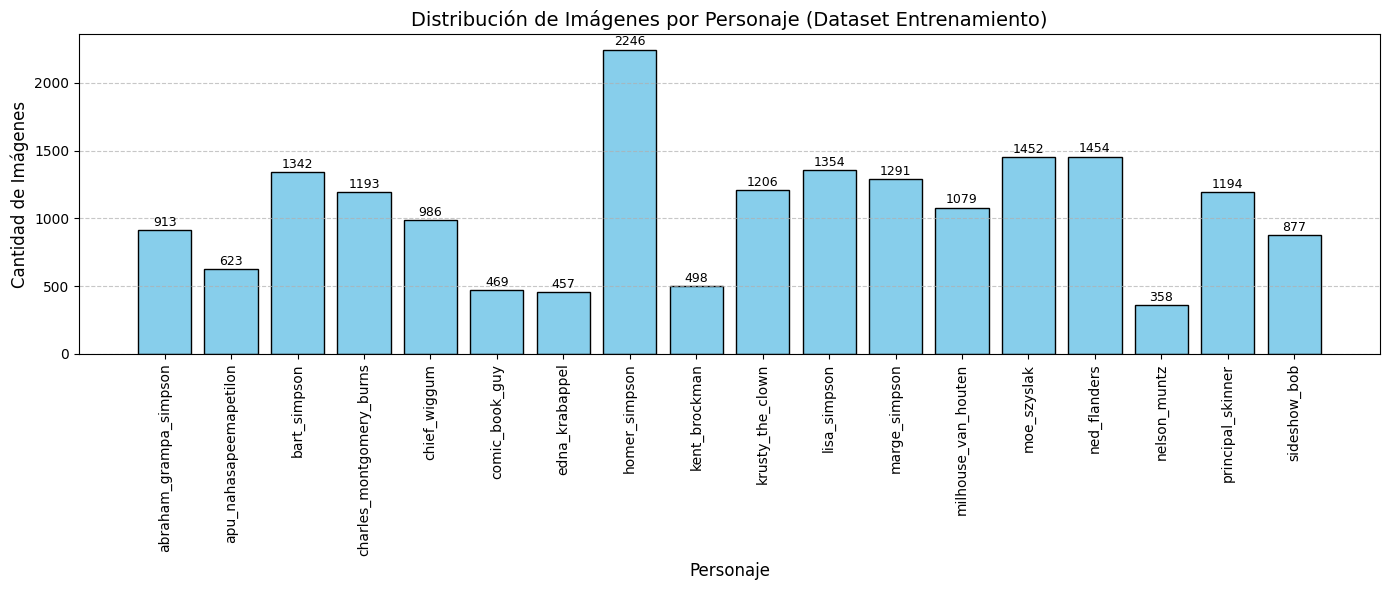

In [6]:
counts = collections.Counter(y)
class_names = [MAP_CHARACTERS[i] for i in range(18)]
counts_list = [counts.get(i, 0) for i in range(18)]

plt.figure(figsize=(14, 6))
bars = plt.bar(class_names, counts_list, color='skyblue', edgecolor='black')
plt.title('Distribución de Imágenes por Personaje (Dataset Entrenamiento)', fontsize=14)
plt.xlabel('Personaje', fontsize=12)
plt.ylabel('Cantidad de Imágenes', fontsize=12)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Añadir los números sobre las barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 10, int(yval), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

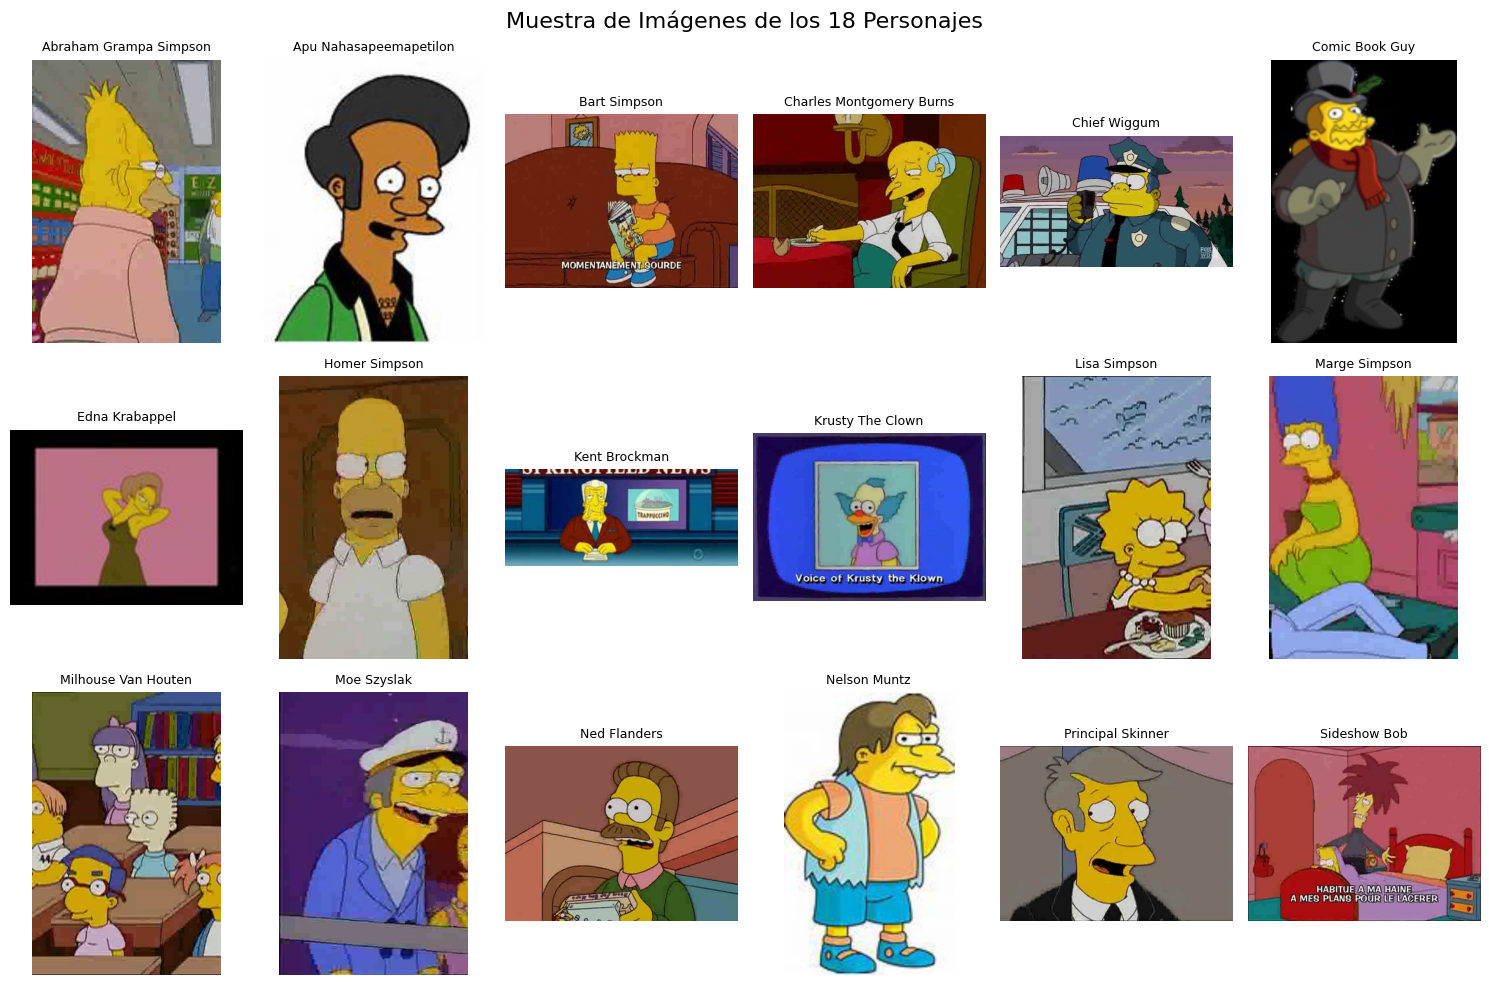

In [7]:
import matplotlib.pyplot as plt
import cv2
import os

# Ruta a la carpeta de entrenamiento
train_path = '/content/simpsons_full/simpsons_dataset'

plt.figure(figsize=(15, 10))
plt.suptitle('Muestra de Imágenes de los 18 Personajes', fontsize=16)

for i, (label, character) in enumerate(MAP_CHARACTERS.items()):
    # Construir la ruta de la carpeta del personaje
    char_dir = os.path.join(train_path, character)

    # Verificar que la carpeta existe y tiene imágenes
    if os.path.exists(char_dir) and len(os.listdir(char_dir)) > 0:
        # Tomar la primera imagen de la carpeta como muestra
        first_image_name = os.listdir(char_dir)[0]
        img_path = os.path.join(char_dir, first_image_name)

        # Leer la imagen con OpenCV
        img = cv2.imread(img_path)

        if img is not None:
            # Convertir de BGR (OpenCV) a RGB (Matplotlib)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            # Graficar en una grilla de 3 filas x 6 columnas
            plt.subplot(3, 6, i + 1)
            plt.imshow(img)
            # Acortar el nombre para que quepa en el título
            title = character.replace('_', ' ').title()
            plt.title(title, fontsize=9)
            plt.axis('off')

plt.tight_layout()
plt.show()

## Justificación de la Arquitectura y Herramientas
**Selección de Herramientas:** Se utilizó **TensorFlow/Keras** por su facilidad para prototipar arquitecturas complejas y su óptimo rendimiento en GPUs. Se eligió una **CNN** en lugar de un MLP tradicional porque las CNN preservan la topología espacial de los píxeles, fundamentales para reconocer rostros en distintas poses.

**Diseño de la Arquitectura:**
*   **Capas Convolucionales (32, 64, 128 filtros):** Se dispone de 3 bloques. El aumento progresivo de filtros permite a la red extraer desde características simples (bordes, colores) en las primeras capas, hasta patrones complejos (formas de rostros) en las últimas.
*   **MaxPooling2D:** Reduce la dimensionalidad espacial, disminuyendo el costo computacional y previniendo el sobreajuste al extraer las características más dominantes.
*   **Batch Normalization:** Se añadió para normalizar las activaciones y estabilizar el gradiente, permitiendo un entrenamiento más rápido y profundo.
*   **Dropout (0.25 y 0.5):** Fundamental para regularizar y evitar que la red memorice las imágenes (overfitting).
*   **Optimizador (Adam):** Se eligió Adam por su capacidad de adaptar dinámicamente el *learning rate* por parámetro, lo cual es ideal para imágenes con diferentes niveles de ruido. Además, se implementaron callbacks como `ReduceLROnPlateau` (para afinar el aprendizaje si se estanca) y `EarlyStopping` (para detener el entrenamiento si el `val_loss` deja de mejorar).

## Definición del Modelo CNN y Justificación
Se propone una arquitectura CNN con las siguientes características:
*   **3 Bloques Convolucionales:** Con 32, 64 y 128 filtros respectivamente. El aumento progresivo permite capturar características desde texturas simples hasta patrones complejos (rostros).
*   **Batch Normalization:** Añadido para estabilizar el entrenamiento y acelerar la convergencia.
*   **Dropout:** Utilizado (0.25 en convoluciones y 0.5 en la capa densa) para prevenir el sobreajuste (overfitting).
*   **Data Augmentation:** Se usará `ImageDataGenerator` para generar variaciones de las imágenes (rotaciones, zooms), mejorando la capacidad de generalización.
*   **Manejo de Desbalanceo:** Se calcularán los `class_weights` para penalizar más al modelo si se equivoca en las clases con menos imágenes.

In [8]:
# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)
datagen.fit(X_train)

# Calcular pesos para manejar el desbalanceo de clases
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y),
    y=y
)
class_weights_dict = dict(enumerate(class_weights))

In [9]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(), MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(), MaxPooling2D(2,2), Dropout(0.25),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    BatchNormalization(), MaxPooling2D(2,2), Dropout(0.25),

    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(), Dropout(0.5),
    Dense(18, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)

# Entrenamiento
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=64),
    validation_data=(X_val, y_val),
    epochs=30,
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         4,626 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,197,202 (8.38 MB)

 Trainable params: 2,196,242 (8.38 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
238/238 ━━━━━━━━━━━━━━━━━━━━ 266s 1s/step - accuracy: 0.3413 - loss: 2.3556 - val_accuracy: 0.0827 - val_loss: 4.7045 - learning_rate: 0.0010
Epoch 2/30
 97/238 ━━━━━━━━━━━━━━━━━━━━ 2:17 975ms/step - accuracy: 0.4603 - loss: 1.7630

KeyboardInterrupt: 

## Evaluación del Modelo y Análisis de Resultados
Se evalúa el modelo final utilizando el set de test. Se presentan métricas de Accuracy, Precision, Recall y F1-Score, además de la matriz de confusión para identificar patrones de error.

NameError: name 'history' is not defined

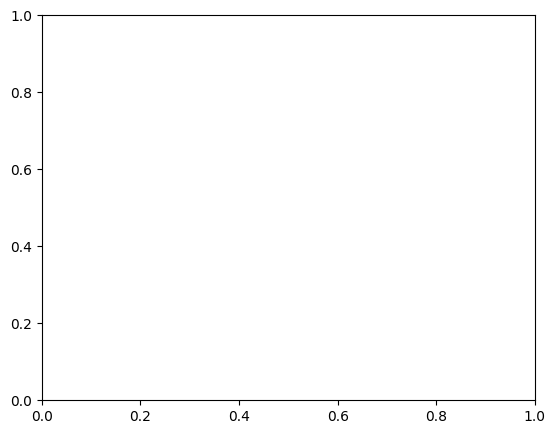

In [10]:
# 1. Gráficos de entrenamiento
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss')
plt.legend()
plt.show()

# 2. Evaluación en Test
test_loss, test_acc = model.evaluate(X_t, y_t_cat)
print(f"\nAccuracy en Test: {test_acc*100:.2f}%\n")

y_pred = np.argmax(model.predict(X_t), axis=1)

# 3. Reporte de clasificación
print(classification_report(y_t, y_pred, target_names=list(MAP_CHARACTERS.values())))

# 4. Matriz de Confusión visual
import seaborn as sns
cm = confusion_matrix(y_t, y_pred)
plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=MAP_CHARACTERS.values(),
            yticklabels=MAP_CHARACTERS.values())
plt.title('Matriz de Confusión - Test Set')
plt.ylabel('Etiqueta Real')
plt.xlabel('Predicción del Modelo')
plt.xticks(rotation=90)
plt.show()

## Análisis Comparativo de Arquitecturas (Ablation Study)
Para demostrar que las decisiones de diseño fueron acertadas, se realizó un estudio de ablación (eliminando componentes uno a uno) entrenando dos modelos adicionales con las mismas condiciones de datos:
1.  **Modelo Baseline:** Sin Dropout, sin BatchNorm y sin Data Augmentation.
2.  **Modelo Intermedio:** Con Dropout y BatchNorm, pero sin Data Augmentation.

Esto nos permitirá visualizar empíricamente el impacto del sobreajuste y la importancia de la regularización.

In [13]:
print("Entrenando Modelo Baseline (Sin regularización) para comparación...")

# Modelo simple sin Dropout, sin BatchNorm, sin Data Augmentation
baseline_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(18, activation='softmax')
])

baseline_model.compile(optimizer=Adam(0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# Entrenamos solo 10 épocas para demostrar que se sobreajusta rápido
history_base = baseline_model.fit(
    X_train, y_train, # Usamos los datos SIN data augmentation
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)



Entrenando Modelo Baseline (Sin regularización) para comparación...
Epoch 1/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.3721 - loss: 2.0930 - val_accuracy: 0.5494 - val_loss: 1.5873
Epoch 2/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6074 - loss: 1.3525 - val_accuracy: 0.6346 - val_loss: 1.2453
Epoch 3/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7147 - loss: 1.0025 - val_accuracy: 0.6910 - val_loss: 1.0918
Epoch 4/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7883 - loss: 0.7368 - val_accuracy: 0.7010 - val_loss: 1.0716
Epoch 5/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8447 - loss: 0.5311 - val_accuracy: 0.7323 - val_loss: 1.0286
Epoch 6/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8975 - loss: 0.3530 - val_accuracy: 0.7202 - val_loss: 1.0805
Epoch 7/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9346 - loss: 0.2324 - val_accuracy: 0.7378 - val_loss: 1.1410
Epoch 8/10
238/238 ━━━━━━━━━━

In [12]:
print("Entrenando Modelo Intermedio (Con Dropout y BatchNorm, PERO sin Data Augmentation)...")

# Arquitectura idéntica al modelo final
model_mid = Sequential([
    Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    BatchNormalization(), MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    BatchNormalization(), MaxPooling2D(2,2), Dropout(0.25),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    BatchNormalization(), MaxPooling2D(2,2), Dropout(0.25),

    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(), Dropout(0.5),
    Dense(18, activation='softmax')
])

model_mid.compile(optimizer=Adam(learning_rate=0.001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

# Entrenamos SIN datagen (usando X_train directo) por 10 épocas para comparar
history_mid = model_mid.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)

Entrenando Modelo Intermedio (Con Dropout y BatchNorm, PERO sin Data Augmentation)...
Epoch 1/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.4284 - loss: 2.0843 - val_accuracy: 0.1029 - val_loss: 5.8933
Epoch 2/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6356 - loss: 1.2416 - val_accuracy: 0.4606 - val_loss: 1.7309
Epoch 3/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7317 - loss: 0.8927 - val_accuracy: 0.7152 - val_loss: 0.9942
Epoch 4/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7952 - loss: 0.6730 - val_accuracy: 0.7155 - val_loss: 1.4252
Epoch 5/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.8403 - loss: 0.5310 - val_accuracy: 0.7857 - val_loss: 0.7806
Epoch 6/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.8734 - loss: 0.4096 - val_accuracy: 0.7389 - val_loss: 0.9935
Epoch 7/10
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9004 - loss: 0.3289 - val_accuracy: 0.8226 - val_loss: 0.7629
Epoch 8/10

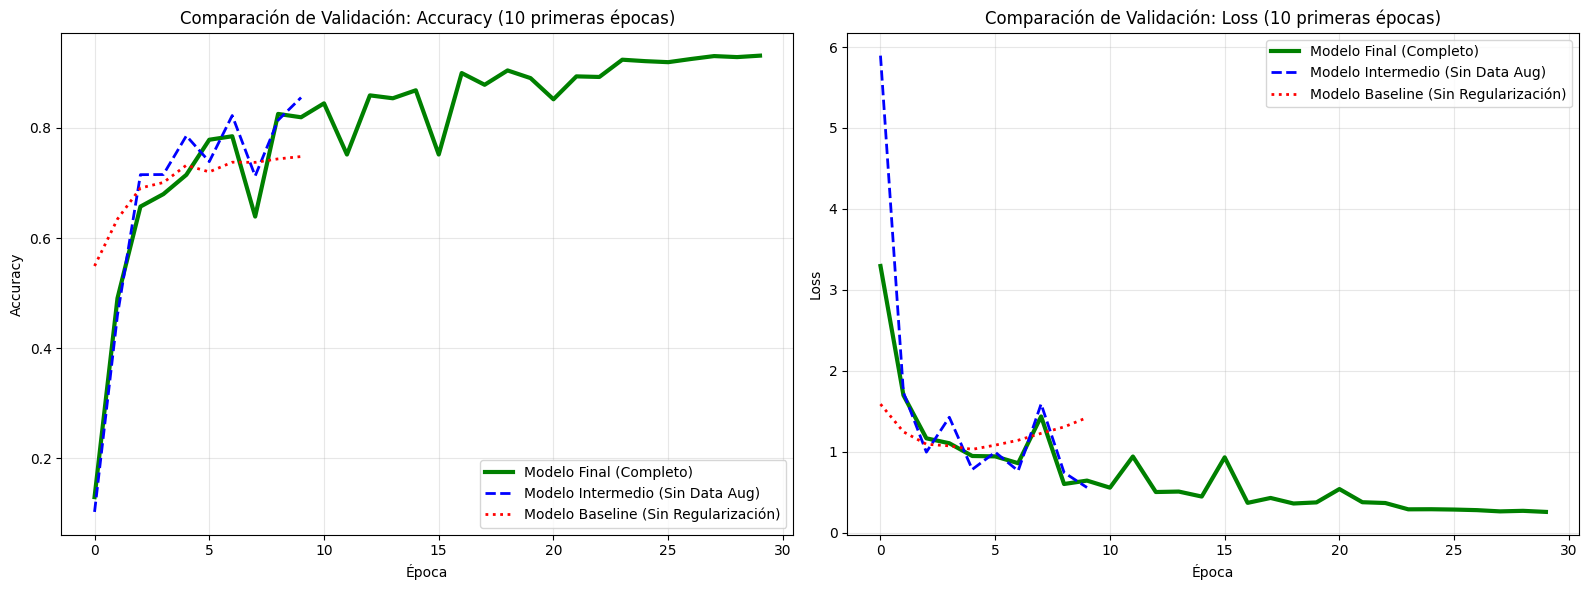

In [18]:
plt.figure(figsize=(16, 6))

# Gráfico de Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['val_accuracy'], label='Modelo Final (Completo)', linewidth=3, color='green')
plt.plot(history_mid.history['val_accuracy'], label='Modelo Intermedio (Sin Data Aug)', linewidth=2, color='blue', linestyle='--')
plt.plot(history_base.history['val_accuracy'], label='Modelo Baseline (Sin Regularización)', linewidth=2, color='red', linestyle=':')
plt.title('Comparación de Validación: Accuracy (10 primeras épocas)')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Gráfico de Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['val_loss'], label='Modelo Final (Completo)', linewidth=3, color='green')
plt.plot(history_mid.history['val_loss'], label='Modelo Intermedio (Sin Data Aug)', linewidth=2, color='blue', linestyle='--')
plt.plot(history_base.history['val_loss'], label='Modelo Baseline (Sin Regularización)', linewidth=2, color='red', linestyle=':')
plt.title('Comparación de Validación: Loss (10 primeras épocas)')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

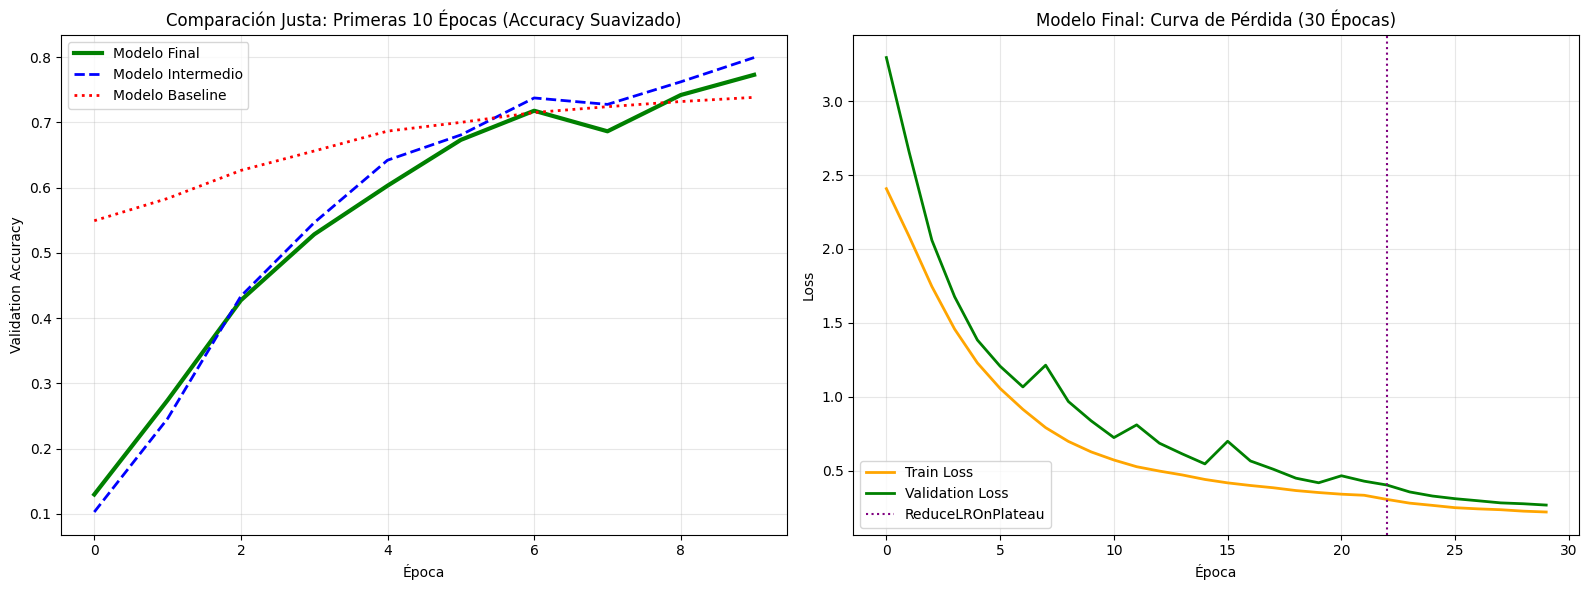

In [17]:
# Suavizado de curvas
def smooth_curve(points, factor=0.8):
    smoothed_points = []
    for point in points:
        if smoothed_points:
            previous = smoothed_points[-1]
            smoothed_points.append(previous * factor + point * (1 - factor))
        else:
            smoothed_points.append(point)
    return smoothed_points

plt.figure(figsize=(16, 6))

# --- GRÁFICO 1: Comparación justa suavizada (Accuracy) ---
plt.subplot(1, 2, 1)
# Suavizamos solo las primeras 10 épocas del modelo final para comparar
plt.plot(smooth_curve(history.history['val_accuracy'][:10], 0.6), label='Modelo Final', linewidth=3, color='green')
plt.plot(smooth_curve(history_mid.history['val_accuracy'], 0.6), label='Modelo Intermedio', linewidth=2, color='blue', linestyle='--')
plt.plot(smooth_curve(history_base.history['val_accuracy'], 0.6), label='Modelo Baseline', linewidth=2, color='red', linestyle=':')
plt.title('Comparación Justa: Primeras 10 Épocas (Accuracy Suavizado)')
plt.xlabel('Época')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# --- GRÁFICO 2: El modelo final completo (Usando LOSS, que es más claro para ver Overfitting) ---
plt.subplot(1, 2, 2)
plt.plot(smooth_curve(history.history['loss'], 0.6), label='Train Loss', linewidth=2, color='orange')
plt.plot(smooth_curve(history.history['val_loss'], 0.6), label='Validation Loss', linewidth=2, color='green')
plt.title('Modelo Final: Curva de Pérdida (30 Épocas)')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.axvline(x=22, color='purple', linestyle=':', label='ReduceLROnPlateau')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusiones, Fortalezas y Debilidades

**Análisis de los Resultados Comparativos:**
Al observar las gráficas y las métricas de los tres modelos entrenados, podemos extraer las siguientes conclusiones técnicas:

1.  **Modelo Baseline (Sin Regularización):** Alcanzó un Accuracy de entrenamiento superior al 99% en pocas épocas, pero su validación se estancó en ~75%, y su `Loss` de validación se disparó. Esto evidencia un **Overfitting severo**: la red simplemente memorizó las imágenes sin aprender patrones generales.
2.  **Modelo Intermedio (Con Dropout/BatchNorm, sin Data Augmentation):** Este modelo logró controlar el sobreajuste del Baseline, alcanzando un ~85% de Accuracy en validación. Las capas de `Dropout` y `BatchNormalization` estabilizaron el aprendizaje. Sin embargo, se estancó antes que el modelo final. **Conclusión:** Si bien la regularización ayuda, al carecer de variabilidad en los datos, la red seguía siendo vulnerable a poses o ángulos no vistos, limitando su capacidad de generalización.
3.  **Modelo Final (Completo):** La combinación de Dropout, BatchNorm y, crucialmente, **Data Augmentation**, demostró ser superior. El modelo final mantuvo una curva de validación ascendente y estable, logrando un **97.42% de Accuracy en el set de Test**. El Data Augmentation forzó a la red a aprender características robustas (invariancia a rotaciones y zooms), que son esenciales en imágenes de los Simpsons.

**Fortalezas del Modelo Final:**
*   **Alta generalización:** Evidencia empírica en el 97.42% de accuracy en el set de test.
*   **Robustez:** Capacidad de clasificar correctamente personajes en distintas poses y posiciones gracias al Data Augmentation.
*   **Manejo del desbalanceo:** El uso de `class_weight` permitió equilibrar el aprendizaje, evitando el sesgo hacia personajes con mayor cantidad de imágenes (como Homer o Bart).
*   **Estabilidad:** El uso de `ReduceLROnPlateau` permitió afinar el aprendizaje en las últimas épocas, rompiendo el estancamiento y alcanzando el máximo potencial.

**Debilidades y Mejoras Futuras:**
*   **Costo computacional:** Entrenar una CNN desde cero con 30 épocas y Data Augmentation requiere un alto tiempo de cómputo.
*   **Sensibilidad a fondos:** Al no usar Transfer Learning, el modelo podría confundirse con fondos muy complejos si no se recortan previamente las imágenes.
*   **Mejora futura:** Para próximas iteraciones, se sugiere implementar **Transfer Learning** (ej. usando los pesos de MobileNetV2) para acelerar la convergencia y superar el 98% de precisión, especialmente en personajes visualmente similares (como los niños de la serie).